---
## Parte 1 — Instalación y entorno

In [ ]:
# ─── Instalación de dependencias ───────────────────────────────────────────
!pip uninstall torch torchvision torchaudio -y --quiet 2>/dev/null; echo ''
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu124 --quiet
!pip install requests transformers huggingface_hub pandas matplotlib numpy --quiet
print('✅ Instalación completada — si ves warnings de CUDA, reinicia el kernel una vez')


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
✅ Instalación completada — si ves warnings de CUDA, reinicia el kernel una vez


### 1.2 Verificación de Recursos (CPU/GPU)
Aquí configuraremos el hardware. Aunque usaremos una API (que corre en servidores externos), es buena práctica verificar si tenemos una GPU disponible para procesos locales auxiliares.

**Resultado esperado:** El nombre de la GPU detectada y la memoria libre disponible.

In [ ]:
# ─── Configuración de GPU ──────────────────────────────────────────────────
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '1'

import requests
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from IPython.display import display, Markdown
import warnings
warnings.filterwarnings('ignore')

import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'🖥️  Dispositivo: {device}')
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    mem_libre = (props.total_memory - torch.cuda.memory_reserved(0)) / 1e9
    print(f'   GPU: {props.name}')
    print(f'   Memoria libre aprox: {mem_libre:.1f} GB')
    print(f'   CUDA: {torch.version.cuda}')

🖥️  Dispositivo: cuda
   GPU: NVIDIA A100-PCIE-40GB
   Memoria libre aprox: 42.4 GB
   CUDA: 12.4


### 2 Configuración de Acceso a la API
Para que el modelo nos responda, necesitamos 'identificarnos'. En esta celda definimos:
1.  **Proveedor**: Por defecto usaremos Hugging Face.
2.  **Modelo**: Llama 3.1 8B, un modelo potente y equilibrado.
3.  **Seguridad**: Cómo el notebook lee tus llaves de acceso (Tokens).

**Resultado esperado:** Un mensaje confirmando que la configuración está lista y el nombre del modelo que se utilizará.

In [ ]:
# ─── Configuración de la API ────────────────────────────────────────────────
# ⚠️  Si acabas de descargar el notebook actualizado, haz:
#     Kernel → Restart Kernel and Run All Cells

# ┌─────────────────────────────────────────────────────────────────────────┐
# │  🌐 ELIGE EL PROVEEDOR DE LA API                                       │
# └─────────────────────────────────────────────────────────────────────────┘
# Opciones: "HUGGINGFACE_PROVIDER", "GROQ_PROVIDER"
API_PROVIDER = "GROQ_PROVIDER" # <-- CAMBIA AQUÍ por GROQ_PROVIDER para usar Groq
GROQ_API_KEY = "" # Valor por defecto si no se encuentra el secreto

# ┌─────────────────────────────────────────────────────────────────────────┐
# │  🧠 ELIGE EL MODELO (POR SU NOMBRE GENÉRICO)                            │
# └─────────────────────────────────────────────────────────────────────────┘
# El sistema intentará mapear este nombre al modelo disponible en el proveedor elegido.
# Opciones comunes: "llama3-8b", "llama3-70b", "mixtral-8x7b", "qwen2.5-72b"
MODELO_GENERICO_ELEGIDO = "llama3-8b" # <-- Cambia aquí el modelo deseado (e.g., "llama3-8b")


# ┌─────────────────────────────────────────────────────────────────────────┐
# │  🔑 INGRESA TUS TOKENS (SOLO NECESITAS EL DEL PROVEEDOR ELEGIDO)       │
# └─────────────────────────────────────────────────────────────────────────┘
#from google.colab import userdata

# Token de Hugging Face (para HuggingFace Inference API)
"""
try:
    HF_TOKEN = userdata.get('HF_TOKEN') # Reemplaza con tu token o usa secrets
except userdata.SecretNotFoundError:
    HF_TOKEN = "hf_XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX" # Valor por defecto si no se encuentra el secreto

# Token de Groq (para GroqCloud API)
try:
    GROQ_API_KEY = userdata.get('GROQ_API_KEY') # Reemplaza con tu token o usa secrets
except userdata.SecretNotFoundError:
    GROQ_API_KEY = "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" # Valor por defecto si no se encuentra el secreto
"""
# ┌─────────────────────────────────────────────────────────────────────────┐
# │  🔧 CONFIGURACIÓN ESPECÍFICA POR PROVEEDOR                             │
# └─────────────────────────────────────────────────────────────────────────┘

# Mapeo de nombres genéricos de modelos a nombres específicos de API
MODEL_NAME_MAPPING = {
    "HUGGINGFACE_PROVIDER": {
        "qwen2.5-72b": "Qwen/Qwen2.5-72B-Instruct",
        "llama3-8b": "meta-llama/Llama-3.1-8B-Instruct", # O similar si Llama 3.1 no está disponible en el router
        "llama3-70b": "meta-llama/Llama-3.1-70B-Instruct",
        "mixtral-8x7b": "mistralai/Mixtral-8x7B-Instruct-v0.1", # Puedes ajustar si hay una versión más reciente
    },
    "GROQ_PROVIDER": {
        "llama3-8b": "llama-3.1-8b-instant",
        "llama3-70b": "llama3-70b-8192",
        "mixtral-8x7b": "mixtral-8x7b-32768",
        # Qwen no está disponible en Groq
    }
}

if API_PROVIDER == "HUGGINGFACE_PROVIDER":
    # Hugging Face Inference API
    # Formato: "organización/modelo"  — el router elige el proveedor más rápido.
    # Puedes forzar un proveedor específico con "organización/modelo:proveedor"

    MODELO_API = MODEL_NAME_MAPPING[API_PROVIDER].get(MODELO_GENERICO_ELEGIDO, "Qwen/Qwen2.5-72B-Instruct")
    if MODELO_API == "Qwen/Qwen2.5-72B-Instruct" and MODELO_GENERICO_ELEGIDO != "qwen2.5-72b":
        print(f"⚠️  Advertencia: Modelo genérico '{MODELO_GENERICO_ELEGIDO}' no tiene mapeo específico para Hugging Face. Usando '{MODELO_API}' por defecto.")

    API_URL    = "https://router.huggingface.co/v1/chat/completions"
    HEADERS    = {
        "Authorization": f"Bearer {HF_TOKEN}",
        "Content-Type": "application/json",
    }

    if HF_TOKEN == "hf_XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX":
        MODO_DEMO = True
        print("⚠️  Token de Hugging Face no configurado — se usarán respuestas simuladas (MODO_DEMO).")
    else:
        MODO_DEMO = False

elif API_PROVIDER == "GROQ_PROVIDER":
    # GroqCloud API

    MODELO_API = MODEL_NAME_MAPPING[API_PROVIDER].get(MODELO_GENERICO_ELEGIDO, "llama3-8b-8192")
    if MODELO_API == "llama3-8b" and MODELO_GENERICO_ELEGIDO != "llama3-8b":
        print(f"⚠️  Advertencia: Modelo genérico '{MODELO_GENERICO_ELEGIDO}' no tiene mapeo específico para Groq. Usando '{MODELO_API}' por defecto.")

    API_URL    = "https://api.groq.com/openai/v1/chat/completions"
    HEADERS    = {
        "Authorization": f"Bearer {GROQ_API_KEY}",
        "Content-Type": "application/json",
    }

    if GROQ_API_KEY == "gsk_XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX":
        MODO_DEMO = True
        print("⚠️  Token de Groq no configurado — se usarán respuestas simuladas (MODO_DEMO).")
    else:
        MODO_DEMO = False

else:
    raise ValueError("API_PROVIDER no reconocido. Elige entre 'HUGGINGFACE_PROVIDER' o 'GROQ_PROVIDER'.")

# ─── Validaciones y mensajes ─────────────────────────────────────────────
if not MODO_DEMO:
    print(f"✅ Configuración lista para {API_PROVIDER}")
    print(f"   Modelo:   {MODELO_API}")
    print(f"   Endpoint: {API_URL}")

    # Mostrar solo una parte del token por seguridad
    if API_PROVIDER == "HUGGINGFACE_PROVIDER":
        print(f"   Token:    {HF_TOKEN[:8]}{'*' * (len(HF_TOKEN) - 8)}")
    elif API_PROVIDER == "GROQ_PROVIDER":
        print(f"   Token:    {GROQ_API_KEY[:8]}{'*' * (len(GROQ_API_KEY) - 8)}")

    # Validaciones para Hugging Face (si es el proveedor activo)
    if API_PROVIDER == "HUGGINGFACE_PROVIDER":
        errores = []
        if 'hf-inference' in API_URL:
            errores.append("❌ API_URL contiene '/hf-inference/' (endpoint obsoleto). "
                           "Haz Kernel → Restart Kernel and Run All Cells.")
        if any(old in MODELO_API for old in ['v0.2', 'v0.3', 'zephyr', 'falcon']):
            errores.append(f"❌ Modelo '{MODELO_API}' puede no estar disponible en el router. "
                           "Usa uno de los modelos listados arriba.")
        if errores:
            for e in errores: print(e)
            raise RuntimeError("Corrige los errores anteriores antes de continuar.")


✅ Configuración lista para GROQ_PROVIDER
   Modelo:   llama-3.1-8b-instant
   Endpoint: https://api.groq.com/openai/v1/chat/completions
   Token:    gsk_6C17************************************************


### 2.1
 Creación del Motor de Comunicación
Definiremos la función `llamar_api`. Esta función es el corazón del módulo: toma tu pregunta (prompt), se la envía al servidor y nos devuelve la respuesta del modelo, cuánto tardó en responder y si hubo algún error.

**Resultado esperado:** Una prueba de conexión exitosa con una latencia baja (menos de 2 segundos generalmente).

### 🛠️ Prueba de Conexión y Diagnóstico

Antes de empezar con el prompting, debemos asegurar que el 'túnel' hacia el modelo está abierto. Esta celda intentará enviar un mensaje de prueba ultra-corto al servidor.

**Importante:**
*   **Si ves 'No definido'**: Significa que debes subir y ejecutar primero la celda **2.1 (Configuración de Acceso a la API)**.
*   **Si ves 'OK'**: Estamos listos para trabajar.
*   **Transparencia**: El sistema te mostrará exactamente qué **Modelo** y qué **Endpoint** estás consumiendo en este momento para evitar confusiones entre Hugging Face y Groq.

In [ ]:
import requests
import time

# Lista de respuestas para simulaciones (Modo Demo)
RESPUESTAS_DEMO = [
    "La inteligencia artificial puede beneficiar a comunidades marginadas mediante diagnóstico médico remoto...",
    "El sesgo algorítmico ocurre cuando un sistema de IA produce resultados injustos para ciertos grupos...",
    "La temperatura controla la aleatoriedad en la generación de texto...",
    "Los riesgos éticos del uso de IA en justicia incluyen: perpetuación de sesgos raciales...",
    "Para un LLM de salud comunitaria rural en México se necesitarían textos médicos en español e indígenas..."
]
_demo_idx = [0]

def llamar_api(prompt, temperatura=0.7, max_tokens=500, system_prompt=None, reintentos=3):
    # Verificar si MODO_DEMO está definido globalmente, si no, por defecto False
    is_demo = globals().get('MODO_DEMO', False)

    if is_demo:
        time.sleep(0.5)
        resp = RESPUESTAS_DEMO[_demo_idx[0] % len(RESPUESTAS_DEMO)]
        _demo_idx[0] += 1
        return resp, 0.5, True

    api_url = globals().get('API_URL', '')
    if not api_url:
        return "[Error: Configuración no encontrada. Ejecuta la celda 2.1 primero]", 0, False

    messages = []
    if system_prompt:
        messages.append({"role": "system", "content": system_prompt})
    messages.append({"role": "user", "content": prompt})

    payload = {
        "model":       globals().get('MODELO_API', 'desconocido'),
        "messages":    messages,
        "temperature": temperatura,
        "max_tokens":  max_tokens,
        "stream":      False,
    }

    headers = globals().get('HEADERS', {})

    for intento in range(reintentos):
        try:
            t0 = time.time()
            respuesta = requests.post(api_url, headers=headers, json=payload, timeout=60)
            latencia = time.time() - t0

            if respuesta.status_code == 200:
                datos = respuesta.json()
                texto = datos['choices'][0]['message']['content'].strip()
                return texto, latencia, True
            elif respuesta.status_code == 429:
                time.sleep(60)
            else:
                return f"[Error {respuesta.status_code}: {respuesta.text[:100]}]", 0, False
        except Exception as e:
            return f"[Error: {e}]", 0, False
    return "[Error: sin respuesta]", 0, False

print("✅ Función llamar_api definida")

# Verificar configuración antes de probar
modo_demo_activo = globals().get('MODO_DEMO', False)
api_provider_check = globals().get('API_PROVIDER')

if not api_provider_check and not modo_demo_activo:
    print("⚠️  ATENCIÓN: No se detectó configuración. Por favor, ejecuta la celda '2.1 Configuración de Acceso a la API' antes de continuar.")
else:
    if modo_demo_activo:
        print("   (Modo DEMO activo — respuestas simuladas)")
    else:
        print(f"🔍 Probando conectividad...")
        print(f"   • API Provider: {globals().get('API_PROVIDER', 'No definido')}")
        print(f"   • Modelo:       {globals().get('MODELO_API', 'No definido')}")
        print(f"   • Endpoint:     {globals().get('API_URL', 'No definido')}")

        resp_test, lat_test, ok = llamar_api(
            "Responde solo con: OK",
            max_tokens=10, temperatura=0.1
        )
        if ok:
            print(f"   ✅ Conexión exitosa — Latencia: {lat_test:.2f}s")
        else:
            print(f"   ❌ Falló la prueba de conexión: {resp_test}")

✅ Función llamar_api definida
🔍 Probando conectividad...
   • API Provider: GROQ_PROVIDER
   • Modelo:       llama-3.1-8b-instant
   • Endpoint:     https://api.groq.com/openai/v1/chat/completions
   ✅ Conexión exitosa — Latencia: 0.33s


---
## Parte 3 — Técnicas de Prompting Efectivo

El **prompting** es el arte de formular instrucciones para obtener las mejores respuestas de un LLM. No es trivial — la forma en que escribes el prompt afecta dramáticamente la calidad, relevancia y formato de la respuesta.

### Técnicas principales

| Técnica | Descripción | Cuándo usarla |
|---------|-------------|---------------|
| **Zero-shot** | Solo la instrucción, sin ejemplos | Tareas simples |
| **Few-shot** | Instrucción + 2-5 ejemplos de entrada/salida | Tareas con formato específico |
| **Chain-of-Thought** | Pedir que el modelo "piense paso a paso" | Razonamiento complejo |
| **Role prompting** | Asignar un rol al modelo | Respuestas especializadas |
| **System prompt** | Instrucciones globales de comportamiento | Controlar tono y contexto |

### Anatomía de un buen prompt

```
[SYSTEM]  Eres un experto en políticas públicas de salud en México...
[CONTEXT] El usuario trabaja en una comunidad rural de Oaxaca...
[TASK]    Explica cómo implementar un programa de telemedicina...
[FORMAT]  Responde en máximo 3 párrafos, usando lenguaje accesible.
[EXAMPLE] Por ejemplo, tu respuesta debe comenzar con "Para implementar..."
```

In [ ]:
# ─── Comparar técnicas de prompting ─────────────────────────────────────────
# Primero definimos diferentes formas de hacer el mismo prompt

PREGUNTA_BASE = "¿Cómo puede la IA ayudar a reducir la desigualdad educativa?"

# ┌─────────────────────────────────────────────────────────────────────────┐
# │  🔧 MODIFICA: cambia la pregunta base o los prompts para experimentar  │
# └─────────────────────────────────────────────────────────────────────────┘

prompts_tecnicas = {

    "1. Zero-shot (básico)": PREGUNTA_BASE,

    "2. Zero-shot (con formato)": (
        f"{PREGUNTA_BASE}\n\n"
        "Responde en 3 puntos concretos, usando lenguaje accesible para el público general. "
        "Incluye al menos un ejemplo aplicable a América Latina."
    ),

    "3. Role prompting": (
        "Eres una especialista en tecnología educativa con 20 años de experiencia "
        "en programas de inclusión digital en comunidades vulnerables de México.\n\n"
        f"{PREGUNTA_BASE}\n\n"
        "Fundamenta tu respuesta en experiencias reales o evidencia existente."
    ),

    "4. Chain-of-Thought": (
        f"{PREGUNTA_BASE}\n\n"
        "Piensa paso a paso: primero identifica las barreras actuales de la educación, "
        "luego señala dónde la IA puede intervenir específicamente, y finalmente menciona "
        "los riesgos que habría que evitar."
    ),

}

print("Prompts definidos. Ejecuta la siguiente celda para enviarlos a la API.")
for nombre, prompt in prompts_tecnicas.items():
    print(f"\n  {nombre}")
    print("-"*60)
    print(f"  (Longitud: {len(prompt)} caracteres)")
    print(f"  {prompt}")
    print("="*60)
    print("\n")

Prompts definidos. Ejecuta la siguiente celda para enviarlos a la API.

  1. Zero-shot (básico)
------------------------------------------------------------
  (Longitud: 60 caracteres)
  ¿Cómo puede la IA ayudar a reducir la desigualdad educativa?



  2. Zero-shot (con formato)
------------------------------------------------------------
  (Longitud: 200 caracteres)
  ¿Cómo puede la IA ayudar a reducir la desigualdad educativa?

Responde en 3 puntos concretos, usando lenguaje accesible para el público general. Incluye al menos un ejemplo aplicable a América Latina.



  3. Role prompting
------------------------------------------------------------
  (Longitud: 277 caracteres)
  Eres una especialista en tecnología educativa con 20 años de experiencia en programas de inclusión digital en comunidades vulnerables de México.

¿Cómo puede la IA ayudar a reducir la desigualdad educativa?

Fundamenta tu respuesta en experiencias reales o evidencia existente.



  4. Chain-of-Thought
---------

### 3.1 Experimentación con Técnicas de Prompting
Vamos a ejecutar una comparativa real. Enviaremos la misma pregunta usando 4 estrategias distintas:
*   **Básica**: Directa.
*   **Con Formato**: Pidiendo puntos específicos.
*   **Rol**: Dándole una personalidad experta.
*   **Razonamiento (CoT)**: Pidiéndole que piense paso a paso.

**Resultado esperado:** Podrás leer las 4 respuestas diferentes y notarás cómo cambia la profundidad del contenido según la instrucción.

In [ ]:
# ─── Ejecutar y comparar las técnicas de prompting ──────────────────────────
resultados_tecnicas = {}

print("Enviando prompts a la API...\n" + "="*60)

for nombre, prompt in prompts_tecnicas.items():
    print(f"\n🔸 {nombre}")

    # El role prompt lleva su descripción de rol como system prompt separado
    sys_prompt = None
    if nombre.startswith("3."):  # Role prompting
        partes = prompt.split("\n\n")
        sys_prompt      = partes[0]
        prompt_usuario  = "\n\n".join(partes[1:])
    else:
        prompt_usuario = prompt

    respuesta, latencia, exito = llamar_api(
        prompt_usuario, temperatura=0.7, max_tokens=300, system_prompt=sys_prompt
    )
    resultados_tecnicas[nombre] = {
        'prompt':    prompt,
        'respuesta': respuesta,
        'latencia':  latencia,
        'exito':     exito,
    }
    print(f"   ⏱️  Latencia: {latencia:.2f}s | Palabras aprox: {len(respuesta.split())}")
    print(f"   📝 {respuesta}..." if len(respuesta) > 220 else f"   📝 {respuesta}")
    print("\n" + "="*60)

print("✅ Comparación completada")

Enviando prompts a la API...

🔸 1. Zero-shot (básico)
   ⏱️  Latencia: 0.84s | Palabras aprox: 197
   📝 La inteligencia artificial (IA) puede ayudar a reducir la desigualdad educativa de varias maneras:

1. **Acceso a la educación remota**: La IA puede permitir que los estudiantes en áreas rurales o de bajos ingresos accedan a una educación de alta calidad a través de plataformas de aprendizaje en línea. Esto puede ayudar a reducir la brecha entre los estudiantes que tienen acceso a recursos educativos y aquellos que no.
2. **Personalización del aprendizaje**: La IA puede ayudar a personalizar el aprendizaje de cada estudiante, adaptando el contenido y la dificultad a las necesidades individuales de cada uno. Esto puede ayudar a que los estudiantes que requieren más apoyo reciban la atención que necesitan, mientras que los estudiantes más avanzados pueden avanzar a un ritmo más rápido.
3. **Acceso a recursos educativos**: La IA puede ayudar a proporcionar acceso a recursos educativos d

Una vez realizado el la consulta al LLM, hay que visualizar y evaluar los resultados

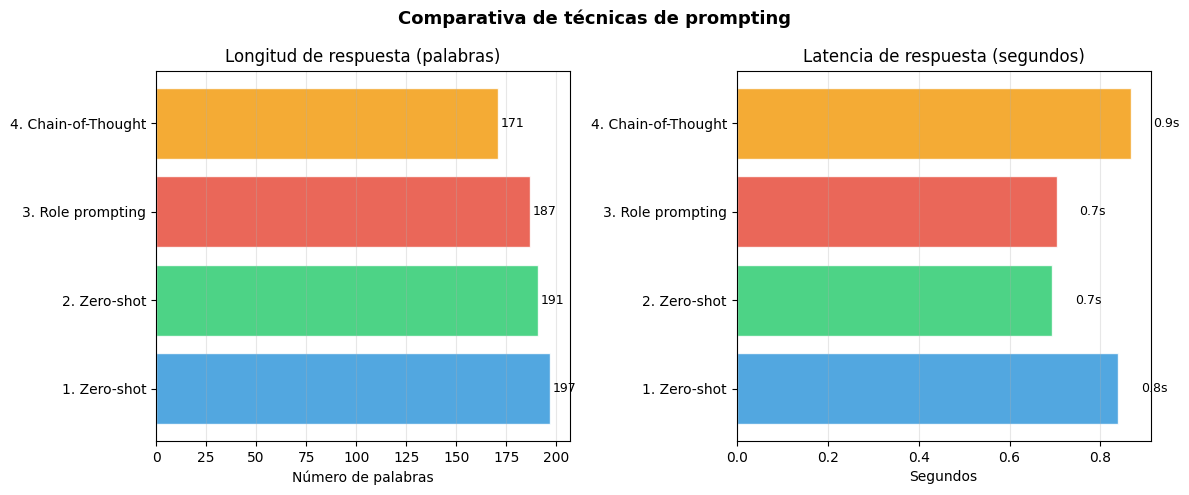

In [ ]:
# ─── Visualizar comparativa de respuestas ───────────────────────────────────
nombres    = list(resultados_tecnicas.keys())
longitudes = [len(r['respuesta'].split()) for r in resultados_tecnicas.values()]
latencias  = [r['latencia'] for r in resultados_tecnicas.values()]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Comparativa de técnicas de prompting', fontsize=13, fontweight='bold')

nombres_cortos = [n.split('(')[0].strip() for n in nombres]
colores = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12']

bars1 = axes[0].barh(nombres_cortos, longitudes, color=colores, alpha=0.85, edgecolor='white')
axes[0].set_title('Longitud de respuesta (palabras)')
axes[0].set_xlabel('Número de palabras')
axes[0].grid(axis='x', alpha=0.3)
for bar, val in zip(bars1, longitudes):
    axes[0].text(val + 1, bar.get_y() + bar.get_height()/2,
                 str(val), va='center', fontsize=9)

bars2 = axes[1].barh(nombres_cortos, latencias, color=colores, alpha=0.85, edgecolor='white')
axes[1].set_title('Latencia de respuesta (segundos)')
axes[1].set_xlabel('Segundos')
axes[1].grid(axis='x', alpha=0.3)
for bar, val in zip(bars2, latencias):
    axes[1].text(val + 0.05, bar.get_y() + bar.get_height()/2,
                 f'{val:.1f}s', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('comparativa_prompting.png', dpi=100, bbox_inches='tight')
plt.show()

---
## Parte 4 — Práctica: Probar ejemplos del dataset con la API

Ahora vamos a tomar **5–10 ejemplos del dataset** incluido en este módulo y evaluarlos con el modelo.

También puedes agregar tus propios ejemplos directamente en la celda del dataset de arriba.

El proceso:
1. Tomar la `instruction` de tu dataset
2. Enviarla a la API con diferentes configuraciones de prompt
3. Comparar la respuesta generada con tu `output` ideal
4. Evaluar la calidad y posibles mejoras

---
### 🔧 ZONA DE EXPERIMENTACIÓN

### 4.1 Carga del Dataset de Evaluación
Para medir qué tan bien funciona el modelo en temas sociales, cargamos un pequeño dataset con preguntas y 'respuestas ideales'. Esto nos servirá de guía para saber si el modelo está diciendo la verdad o alucinando.

**Resultado esperado:** Un listado de los 10 temas disponibles en el dataset.

In [ ]:
# ─── Dataset de ejemplos — autocontenido en este módulo ─────────────────────
# No necesitas haber completado el Módulo 3 para usar este notebook.
#
# El dataset ya incluye 10 ejemplos listos sobre IA para el bien social.
# Al final de la lista puedes AGREGAR TUS PROPIOS ejemplos.

mi_dataset = [
    # ── Ejemplos listos ──────────────────────────────────────────────────────
    {
        "instruction": "¿Qué es la inteligencia artificial y cómo puede beneficiar a comunidades marginadas en América Latina?",
        "input": "",
        "output": "La IA es el desarrollo de sistemas que realizan tareas que normalmente requieren inteligencia humana. "
                  "Para comunidades marginadas puede aplicarse en: diagnóstico médico remoto sin especialistas presenciales, "
                  "traducción automática de lenguas indígenas para acceder a servicios públicos, "
                  "y sistemas de alerta temprana para desastres naturales en zonas rurales."
    },
    {
        "instruction": "¿Qué es el sesgo algorítmico y cuál es un ejemplo concreto en el contexto latinoamericano?",
        "input": "",
        "output": "El sesgo algorítmico ocurre cuando un sistema de IA produce resultados sistemáticamente injustos "
                  "para ciertos grupos, porque fue entrenado con datos históricos que reflejan desigualdades. "
                  "En América Latina, un ejemplo son los modelos de crédito que niegan préstamos "
                  "desproporcionadamente a comunidades indígenas o afrodescendientes, no por mayor riesgo real, "
                  "sino porque históricamente han tenido menos acceso al sistema financiero formal."
    },
    {
        "instruction": "Explica qué es el fine-tuning de un modelo de lenguaje y para qué sirve.",
        "input": "",
        "output": "El fine-tuning (ajuste fino) es el proceso de tomar un modelo de lenguaje ya entrenado en grandes "
                  "cantidades de texto y adaptarlo a una tarea específica con un conjunto de datos más pequeño. "
                  "Es mucho más eficiente que entrenar desde cero: en lugar de enseñarle todo el lenguaje, "
                  "solo se le enseña el estilo, vocabulario y conocimiento específico de una tarea concreta, "
                  "como responder preguntas médicas o redactar informes de impacto social."
    },
    {
        "instruction": "¿Cuáles son los principales riesgos éticos del uso de IA en sistemas de justicia penal?",
        "input": "",
        "output": "Los principales riesgos incluyen: (1) Perpetuación de sesgos raciales y socioeconómicos al entrenar "
                  "con datos históricos de sistemas policiales y judiciales ya discriminatorios; "
                  "(2) Falta de explicabilidad en decisiones que afectan libertades individuales; "
                  "(3) Reemplazo del juicio humano en contextos que requieren consideración del contexto individual; "
                  "(4) Concentración de poder en las organizaciones que controlan los algoritmos, "
                  "sin mecanismos de rendición de cuentas hacia las comunidades afectadas."
    },
    {
        "instruction": "¿Cómo puede la IA ayudar a reducir la desigualdad educativa en zonas rurales?",
        "input": "Considera el contexto de México con acceso limitado a internet en comunidades alejadas.",
        "output": "La IA puede reducir la desigualdad educativa mediante: sistemas de tutoría personalizada "
                  "que funcionan offline en dispositivos de bajo costo; modelos de lenguaje compactos "
                  "que generan materiales didácticos en lenguas indígenas; herramientas de diagnóstico "
                  "de aprendizaje que ayudan a maestros rurales a identificar estudiantes en riesgo; "
                  "y plataformas de capacitación docente accesibles vía SMS o radio comunitaria."
    },
    {
        "instruction": "¿Qué datos se necesitarían para entrenar un LLM especializado en salud comunitaria rural en México?",
        "input": "",
        "output": "Se necesitarían: (1) Textos médicos en español y en las lenguas indígenas de la región objetivo; "
                  "(2) Registros anonimizados de consultas del IMSS Bienestar en zonas rurales; "
                  "(3) Guías clínicas adaptadas a las enfermedades prevalentes como diabetes, desnutrición "
                  "e infecciones respiratorias; (4) Conocimiento de medicina tradicional documentado "
                  "con consentimiento de las comunidades; (5) Preguntas frecuentes de pacientes rurales "
                  "recopiladas con promotores de salud comunitarios."
    },
    {
        "instruction": "¿Qué es la privacidad diferencial y cómo protege los datos de comunidades vulnerables?",
        "input": "",
        "output": "La privacidad diferencial es una técnica matemática que permite analizar datos "
                  "y entrenar modelos de IA sin revelar información de personas individuales. "
                  "Funciona añadiendo 'ruido' estadístico controlado a los datos, de manera que "
                  "los resultados del modelo siguen siendo útiles pero nadie puede identificar "
                  "a una persona específica en el conjunto de datos. Es especialmente importante "
                  "para comunidades vulnerables cuyos datos de salud, migración o situación económica "
                  "podrían usarse en su contra si se expusieran."
    },
    {
        "instruction": "Describe tres aplicaciones concretas de IA para el monitoreo ambiental en América Latina.",
        "input": "",
        "output": "(1) Detección de deforestación: modelos de visión computacional analizan imágenes satelitales "
                  "para identificar pérdida de cobertura forestal en tiempo casi real, como el sistema "
                  "DETER del INPE en la Amazonía brasileña. "
                  "(2) Monitoreo de calidad del agua: sensores IoT combinados con ML detectan contaminación "
                  "en ríos de zonas mineras antes de que afecte comunidades aguas abajo. "
                  "(3) Predicción de sequías: modelos climáticos con aprendizaje automático anticipan "
                  "períodos de escasez hídrica para que comunidades agrícolas planifiquen con semanas de anticipación."
    },
    {
        "instruction": "¿Qué significa que un modelo de IA sea 'explicable' y por qué es importante para el bien social?",
        "input": "",
        "output": "Un modelo explicable (o interpretable) es aquel que puede justificar sus predicciones "
                  "en términos comprensibles para las personas afectadas. Por ejemplo, en lugar de decir "
                  "'el crédito fue denegado', un modelo explicable diría 'el crédito fue denegado porque "
                  "el ingreso mensual es menor al mínimo requerido y no hay historial crediticio previo'. "
                  "Para el bien social es fundamental porque: permite impugnar decisiones incorrectas, "
                  "genera confianza en comunidades históricamente excluidas, y facilita la detección "
                  "de sesgos por parte de auditores externos."
    },
    {
        "instruction": "¿Cómo se puede evaluar si un sistema de IA es justo para diferentes grupos de la población?",
        "input": "",
        "output": "La evaluación de equidad en IA se hace mediante métricas específicas aplicadas por separado "
                  "a diferentes grupos demográficos. Las más comunes son: "
                  "(1) Paridad demográfica: el modelo debe tener tasas de predicción positiva similares entre grupos; "
                  "(2) Igualdad de oportunidades: misma tasa de verdaderos positivos para todos los grupos; "
                  "(3) Paridad de error: tasas similares de falsos positivos y negativos. "
                  "Es crucial involucrar a las comunidades afectadas en definir qué significa 'justo' "
                  "en su contexto específico, ya que estas métricas pueden ser mutuamente excluyentes."
    },
    # ── Agrega tus propios ejemplos aquí ─────────────────────────────────────
    # Copia y pega el bloque de abajo, quita el # y rellena con tu pregunta y respuesta:
    #
    # {
    #     "instruction": "[TU PREGUNTA O TAREA]",
    #     "input": "[CONTEXTO ADICIONAL — puede dejarse vacío '']",
    #     "output": "[LA RESPUESTA IDEAL QUE ESPERAS DEL MODELO]"
    # },
]

print(f"✅ Dataset listo: {len(mi_dataset)} ejemplos")
print(f"\nTemas disponibles:")
for i, ej in enumerate(mi_dataset):
    print(f"  [{i}] {ej['instruction'][:200]}...")


✅ Dataset listo: 10 ejemplos

Temas disponibles:
  [0] ¿Qué es la inteligencia artificial y cómo puede beneficiar a comunidades marginadas en América Latina?...
  [1] ¿Qué es el sesgo algorítmico y cuál es un ejemplo concreto en el contexto latinoamericano?...
  [2] Explica qué es el fine-tuning de un modelo de lenguaje y para qué sirve....
  [3] ¿Cuáles son los principales riesgos éticos del uso de IA en sistemas de justicia penal?...
  [4] ¿Cómo puede la IA ayudar a reducir la desigualdad educativa en zonas rurales?...
  [5] ¿Qué datos se necesitarían para entrenar un LLM especializado en salud comunitaria rural en México?...
  [6] ¿Qué es la privacidad diferencial y cómo protege los datos de comunidades vulnerables?...
  [7] Describe tres aplicaciones concretas de IA para el monitoreo ambiental en América Latina....
  [8] ¿Qué significa que un modelo de IA sea 'explicable' y por qué es importante para el bien social?...
  [9] ¿Cómo se puede evaluar si un sistema de IA es justo para 

A partir de los ejemplos anteriores, se seleccionan 5 para evaluarlos.

In [ ]:
# ─── Seleccionar ejemplos del dataset para evaluar ──────────────────────────

# ┌─────────────────────────────────────────────────────────────────────────┐
# │  🔧 MODIFICA: elige qué ejemplos enviar a la API                        │
# └─────────────────────────────────────────────────────────────────────────┘

# Opción A — usar los primeros N ejemplos del dataset
INDICES_SELECCIONADOS = list(range(min(5, len(mi_dataset))))

# Opción B — elegir ejemplos específicos por índice (descomenta y ajusta):
# INDICES_SELECCIONADOS = [0, 2, 5, 8]  # ← cambia los números

# ┌─────────────────────────────────────────────────────────────────────────┐
# │  🔧 MODIFICA: parámetros de la llamada a la API                        │
# └─────────────────────────────────────────────────────────────────────────┘

TEMPERATURA_EXPERIMENTO = 0.7   # ← prueba 0.3 (más preciso) o 1.2 (más creativo)
MAX_TOKENS_EXPERIMENTO  = 1024   # ← ajusta la longitud máxima de respuesta

# System prompt — define el comportamiento global del modelo para todos los ejemplos
SYSTEM_PROMPT = """Eres un experto en inteligencia artificial aplicada al bien social en América Latina.
Responde de forma clara, precisa y accesible para público general.
Cuando sea relevante, incluye ejemplos del contexto latinoamericano.
Evita tecnicismos innecesarios sin antes explicarlos."""

# ─────────────────────────────────────────────────────────────────────────

ejemplos_a_evaluar = [mi_dataset[i] for i in INDICES_SELECCIONADOS]
print(f"📋 Evaluando {len(ejemplos_a_evaluar)} ejemplos")
print(f"⚙️  Temperatura: {TEMPERATURA_EXPERIMENTO} | Max tokens: {MAX_TOKENS_EXPERIMENTO}")
print(f"\nEjemplos seleccionados:")
for i, ej in enumerate(ejemplos_a_evaluar):
    print(f"  {i+1}. [{INDICES_SELECCIONADOS[i]}] {ej['instruction'][:200]}...")


📋 Evaluando 5 ejemplos
⚙️  Temperatura: 0.7 | Max tokens: 1024

Ejemplos seleccionados:
  1. [0] ¿Qué es la inteligencia artificial y cómo puede beneficiar a comunidades marginadas en América Latina?...
  2. [1] ¿Qué es el sesgo algorítmico y cuál es un ejemplo concreto en el contexto latinoamericano?...
  3. [2] Explica qué es el fine-tuning de un modelo de lenguaje y para qué sirve....
  4. [3] ¿Cuáles son los principales riesgos éticos del uso de IA en sistemas de justicia penal?...
  5. [4] ¿Cómo puede la IA ayudar a reducir la desigualdad educativa en zonas rurales?...


A partir de los ejemplos seleccionados, se hace su evaluación

In [ ]:
# ─── Función construir_prompt y bucle de evaluación ────────────────────────

def construir_prompt(instruccion, contexto=""):
    """Arma el mensaje de usuario. El system_prompt se pasa por separado a llamar_api."""
    partes = [instruccion]
    if contexto:
        partes.append(f"\n[Contexto adicional]\n{contexto}")
    return "\n".join(partes)


resultados_evaluacion = []

print("Procesando ejemplos con la API...\n")

for i, ejemplo in enumerate(ejemplos_a_evaluar):
    print(f"─── Ejemplo {i+1}/{len(ejemplos_a_evaluar)} ───────────────────────────────")
    print(f"📝 Instrucción: {ejemplo['instruction']}...")

    prompt_usuario = construir_prompt(
        instruccion=ejemplo['instruction'],
        contexto=ejemplo.get('input', ''),
    )

    respuesta_modelo, latencia, exito = llamar_api(
        prompt_usuario,
        temperatura=TEMPERATURA_EXPERIMENTO,
        max_tokens=MAX_TOKENS_EXPERIMENTO,
        system_prompt=SYSTEM_PROMPT,
    )

    print(f"🤖 Respuesta modelo: {respuesta_modelo}...")
    print(f"✅ Respuesta ideal:  {ejemplo['output']}...")
    print(f"⏱️  Latencia: {latencia:.2f}s\n")

    resultados_evaluacion.append({
        'instruccion':      ejemplo['instruction'],
        'contexto':         ejemplo.get('input', ''),
        'respuesta_ideal':  ejemplo['output'],
        'respuesta_modelo': respuesta_modelo,
        'latencia':         latencia,
        'exito':            exito,
        'temperatura':      TEMPERATURA_EXPERIMENTO,
    })

print(f"\n✅ Evaluación completada: {len(resultados_evaluacion)} ejemplos procesados")


Procesando ejemplos con la API...

─── Ejemplo 1/5 ───────────────────────────────
📝 Instrucción: ¿Qué es la inteligencia artificial y cómo puede beneficiar a comunidades marginadas en América Latina?...
🤖 Respuesta modelo: La inteligencia artificial (IA) se refiere a la capacidad de las computadoras para realizar tareas que suelen requerir inteligencia humana, como aprender, razonar y tomar decisiones. En América Latina, la IA puede beneficiar a comunidades marginadas de varias maneras:

1. **Acceso a servicios de salud**: La IA puede ayudar a mejorar la atención médica en áreas rurales o con pocos recursos. Por ejemplo, un sistema de IA puede analizar imágenes de radiografías para detectar enfermedades como el cáncer, lo que puede ayudar a diagnosticar y tratar a pacientes de manera más efectiva.

2. **Educación inclusiva**: La IA puede ayudar a mejorar la educación en áreas marginadas mediante la creación de herramientas de aprendizaje personalizadas. Por ejemplo, un sistema de IA p

### 4.2 Análisis de Calidad y Visualización
Tras obtener las respuestas, generaremos gráficos que comparan la 'Precisión', 'Claridad' y 'Contexto Social'. Esto ayuda a visualizar dónde el modelo es fuerte y dónde necesita mejores instrucciones.

**Resultado esperado:** Gráficos de barras y de radar (araña) mostrando los promedios de desempeño.

### 4.2 Evaluación Cualitativa: El Ojo Humano

Aunque el modelo responda rápido, la verdadera prueba es si la información es útil y correcta para el mundo real. En esta sección:

1.  **Analizamos** la respuesta del modelo frente a la 'respuesta ideal'.
2.  **Calificamos** en una escala del 1 al 5 cuatro dimensiones críticas: **Precisión**, **Completitud**, **Claridad** y **Contexto Latinoamericano**.

**Resultado esperado:** Una tabla guía que te servirá para llenar tus evaluaciones en la siguiente celda y así generar estadísticas de desempeño.

In [ ]:
# ─── Evaluación cualitativa: tabla de resultados ────────────────────────────
# Ahora TÚ evalúas la calidad. Esta es la parte más importante del módulo.
#
# Para cada ejemplo, asigna una puntuación del 1 al 5 en cada dimensión:
#   1 = Muy deficiente
#   3 = Aceptable
#   5 = Excelente

print("="*65)
print("EVALUACIÓN CUALITATIVA — COMPLETA LA SIGUIENTE TABLA")
print("="*65)

print(f"\n{'#':^4} | {'Precisión':^10} | {'Completitud':^12} | {'Claridad':^9} | {'Contextual':^11} | {'Notas'}")
print("-" * 65)
for i in range(len(resultados_evaluacion)):
    print(f"  {i+1}  |    ___    |     ___     |   ___   |    ___    | ")

print("")
print("Definiciones:")
print("  Precisión:    ¿La respuesta es factualmente correcta?")
print("  Completitud:  ¿Cubre todos los aspectos importantes?")
print("  Claridad:     ¿Es fácil de entender para el público general?")
print("  Contextual:   ¿Es relevante para el contexto latinoamericano?")

EVALUACIÓN CUALITATIVA — COMPLETA LA SIGUIENTE TABLA

 #   | Precisión  | Completitud  | Claridad  | Contextual  | Notas
-----------------------------------------------------------------
  1  |    ___    |     ___     |   ___   |    ___    | 
  2  |    ___    |     ___     |   ___   |    ___    | 
  3  |    ___    |     ___     |   ___   |    ___    | 
  4  |    ___    |     ___     |   ___   |    ___    | 
  5  |    ___    |     ___     |   ___   |    ___    | 

Definiciones:
  Precisión:    ¿La respuesta es factualmente correcta?
  Completitud:  ¿Cubre todos los aspectos importantes?
  Claridad:     ¿Es fácil de entender para el público general?
  Contextual:   ¿Es relevante para el contexto latinoamericano?


A pesar de que los LLM dan respuestas, es al humano al que le corresponde determinar la validez de lo respondido!

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 🔧 INGRESA TUS EVALUACIONES AQUÍ
# ─────────────────────────────────────────────────────────────────────────────
# Para cada ejemplo, asigna puntuaciones del 1 al 5.
# Agrega una entrada por cada ejemplo evaluado.

mis_evaluaciones = [
    # Formato: {"precision": X, "completitud": X, "claridad": X, "contextual": X, "notas": "..."}
    {"precision": 4, "completitud": 3, "claridad": 4, "contextual": 3,
     "notas": "Buena respuesta pero falta contexto latinoamericano"},   # Ejemplo 1
    {"precision": 5, "completitud": 4, "claridad": 5, "contextual": 4,
     "notas": "Excelente, bien estructurado"},                          # Ejemplo 2
    {"precision": 3, "completitud": 3, "claridad": 4, "contextual": 2,
     "notas": "Correcta pero demasiado genérica"},                      # Ejemplo 3
    {"precision": 4, "completitud": 5, "claridad": 3, "contextual": 4,
     "notas": "Técnicamente buena pero difícil de entender"},           # Ejemplo 4
    {"precision": 5, "completitud": 4, "claridad": 5, "contextual": 5,
     "notas": "Muy relevante para el contexto"},                        # Ejemplo 5
    # ← MODIFICA LOS VALORES SEGÚN TU EVALUACIÓN
]

# Asegurar que hay una evaluación por ejemplo
mis_evaluaciones = mis_evaluaciones[:len(resultados_evaluacion)]
while len(mis_evaluaciones) < len(resultados_evaluacion):
    mis_evaluaciones.append({"precision": 3, "completitud": 3, "claridad": 3, "contextual": 3, "notas": ""})

# Calcular promedios
dimensiones = ['precision', 'completitud', 'claridad', 'contextual']
promedios = {d: np.mean([e[d] for e in mis_evaluaciones]) for d in dimensiones}

print("📊 Promedios de calidad del modelo:")
for dim, val in promedios.items():
    barra = '█' * int(val) + '░' * (5 - int(val))
    print(f"   {dim.capitalize():<15} {barra}  {val:.1f}/5")

print(f"\n   Puntuación global: {np.mean(list(promedios.values())):.1f}/5")

📊 Promedios de calidad del modelo:
   Precision       ████░  4.2/5
   Completitud     ███░░  3.8/5
   Claridad        ████░  4.2/5
   Contextual      ███░░  3.6/5

   Puntuación global: 3.9/5


Y lo anterior se verá mejor de manera gráfica

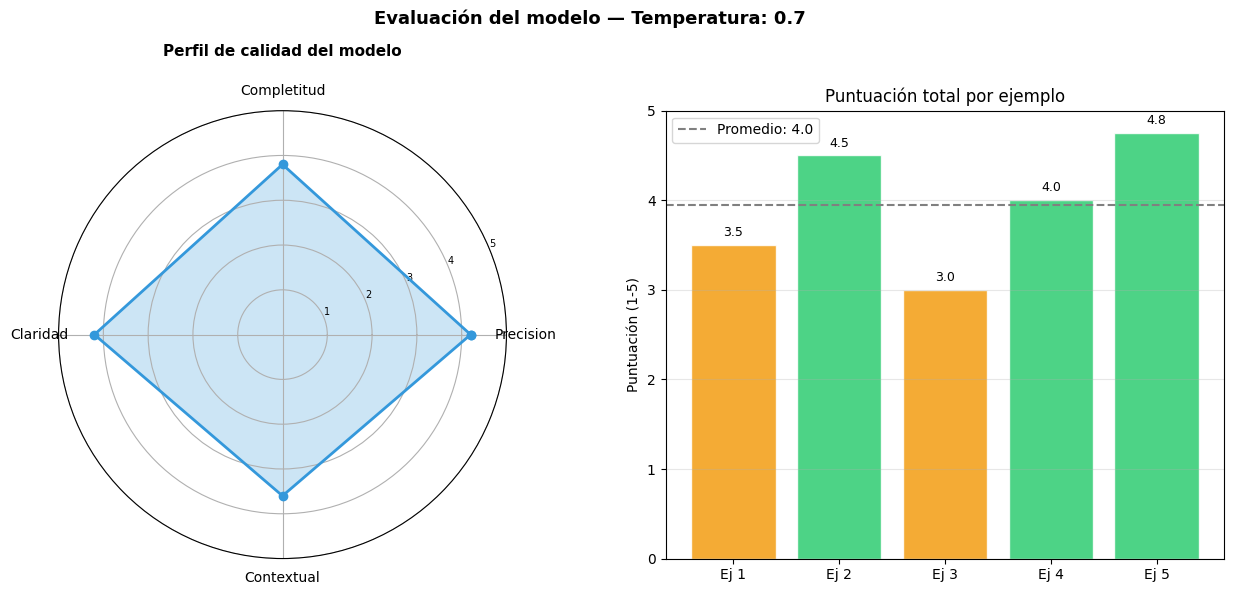

In [ ]:
# ─── Visualizar resultados de la evaluación ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
fig.suptitle(f'Evaluación del modelo — Temperatura: {TEMPERATURA_EXPERIMENTO}',
             fontsize=13, fontweight='bold')

# Radar chart (gráfica de araña) para métricas de calidad
categorias = list(promedios.keys())
valores     = list(promedios.values())
N = len(categorias)
angulos = [n / float(N) * 2 * np.pi for n in range(N)]
angulos += angulos[:1]
valores_plot = valores + valores[:1]

ax = axes[0]
ax_polar = fig.add_subplot(121, polar=True)
ax.remove()  # Quitar el axis plano
ax_polar.set_position(axes[0].get_position())

ax_polar.plot(angulos, valores_plot, 'o-', linewidth=2, color='#3498db')
ax_polar.fill(angulos, valores_plot, alpha=0.25, color='#3498db')
ax_polar.set_xticks(angulos[:-1])
ax_polar.set_xticklabels([c.capitalize() for c in categorias], size=10)
ax_polar.set_ylim(0, 5)
ax_polar.set_yticks([1, 2, 3, 4, 5])
ax_polar.set_yticklabels(['1', '2', '3', '4', '5'], size=7)
ax_polar.set_title('Perfil de calidad del modelo', size=11, fontweight='bold', pad=20)

# Puntuaciones por ejemplo
indices = [f"Ej {i+1}" for i in range(len(mis_evaluaciones))]
punts_totales = [np.mean([e[d] for d in dimensiones]) for e in mis_evaluaciones]

colores_bars = ['#2ecc71' if p >= 4 else '#f39c12' if p >= 3 else '#e74c3c' for p in punts_totales]
axes[1].bar(indices, punts_totales, color=colores_bars, alpha=0.85, edgecolor='white')
axes[1].axhline(y=np.mean(punts_totales), color='gray', linestyle='--', linewidth=1.5,
                label=f'Promedio: {np.mean(punts_totales):.1f}')
axes[1].set_ylim(0, 5)
axes[1].set_title('Puntuación total por ejemplo')
axes[1].set_ylabel('Puntuación (1-5)')
axes[1].legend(); axes[1].grid(axis='y', alpha=0.3)
for bar, val in zip(axes[1].patches, punts_totales):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.1,
                 f'{val:.1f}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('evaluacion_modelo.png', dpi=100, bbox_inches='tight')
plt.show()

### 4.3 Experimento de Temperatura: ¿Creatividad o Precisión?

La **Temperatura** es un hiperparámetro que controla qué tan 'arriesgado' o creativo es el modelo al elegir la siguiente palabra:

*   **Baja (0.1 - 0.3)**: El modelo es determinista y conservador. Ideal para datos fácticos.
*   **Alta (1.0 - 1.5)**: El modelo es más creativo y variado, pero puede inventar cosas (alucinar).

En la siguiente celda, enviaremos la misma pregunta tres veces con diferentes temperaturas para que compares visualmente cómo cambia el lenguaje del modelo.

**Resultado esperado:** Verás tres respuestas. Notarás que la de temperatura 0.2 es muy directa y la de 1.2 suele ser más extensa o con una redacción más fluida.

In [ ]:
# ─── Efecto de la temperatura: comparación directa ──────────────────────────

# ┌─────────────────────────────────────────────────────────────────────────┐
# │  🔧 MODIFICA: elige el ejemplo y las temperaturas a comparar           │
# └─────────────────────────────────────────────────────────────────────────┘

INDICE_EJEMPLO_TEMP   = 0    # ← índice del ejemplo en mi_dataset (0–9 para los predefinidos)
TEMPERATURAS_COMPARAR = [0.2, 0.7, 1.2]  # ← agrega o cambia temperaturas

# ─────────────────────────────────────────────────────────────────────────

ejemplo_temp   = mi_dataset[INDICE_EJEMPLO_TEMP]
prompt_usuario = construir_prompt(ejemplo_temp['instruction'], ejemplo_temp.get('input', ''))

print(f"Instrucción [{INDICE_EJEMPLO_TEMP}]: {ejemplo_temp['instruction'][:80]}...")
print("\nComparando respuestas con diferentes temperaturas:\n")

for temp in TEMPERATURAS_COMPARAR:
    resp, lat, _ = llamar_api(
        prompt_usuario,
        temperatura=temp,
        max_tokens=250,
        system_prompt=SYSTEM_PROMPT,
    )
    print(f"🌡️  Temperatura {temp}:")
    print(f"   {resp[:300]}..." if len(resp) > 300 else f"   {resp}")
    print()


Instrucción [0]: ¿Qué es la inteligencia artificial y cómo puede beneficiar a comunidades margina...

Comparando respuestas con diferentes temperaturas:

🌡️  Temperatura 0.2:
   La inteligencia artificial (IA) es una rama de la informática que se enfoca en desarrollar sistemas y algoritmos que pueden aprender, razonar y tomar decisiones de manera autónoma, imitando la forma en que funcionan los seres humanos. En América Latina, la IA puede beneficiar a comunidades marginada...

🌡️  Temperatura 0.7:
   La inteligencia artificial (IA) es una rama de la informática que se enfoca en crear sistemas capaces de realizar tareas que suelen requerir habilidades y juicios humanos, como la visión, el lenguaje, el aprendizaje y el razonamiento. La IA utiliza algoritmos y técnicas de procesamiento de datos par...

🌡️  Temperatura 1.2:
   La inteligencia artificial (IA) es un campo de la informática que busca desarrollar máquinas capaces de realizar tareas que típicamente requieren inteligencia human

### 🔍 Interpretando el Experimento de Temperatura

En la celda anterior, hemos ejecutado el mismo prompt bajo tres configuraciones distintas. Aquí te explicamos qué observar:

*   **Temperatura 0.2 (Baja):** Notarás que la respuesta es muy estructurada y predecible. El modelo elige las palabras con mayor probabilidad, lo que reduce el riesgo de inventar datos pero puede hacer que el texto se sienta algo 'robótico'.
*   **Temperatura 0.7 (Media):** Es el equilibrio estándar. Proporciona fluidez narrativa manteniendo la coherencia con los hechos.
*   **Temperatura 1.2 (Alta):** Aquí el modelo toma más 'riesgos'. Las frases pueden ser más variadas y creativas, pero ¡cuidado! Es más propenso a las **alucinaciones** (inventar hechos que suenan reales pero no lo son).

**¿Qué configuración prefieres para un asistente de salud comunitaria?** Generalmente, para temas sociales y médicos, se prefieren temperaturas bajas para garantizar la veracidad.

In [ ]:
# ─── Guardar resultados completos de la sesión ──────────────────────────────
reporte = {
    'modelo':              MODELO_API,
    'temperatura_base':    TEMPERATURA_EXPERIMENTO,
    'total_ejemplos':      len(resultados_evaluacion),
    'promedios_calidad':   promedios,
    'puntuacion_global':   np.mean(list(promedios.values())),
    'evaluaciones_detalle': [
        {
            **resultado,
            **evaluacion
        }
        for resultado, evaluacion in zip(resultados_evaluacion, mis_evaluaciones)
    ]
}

with open('reporte_evaluacion_modulo4.json', 'w', encoding='utf-8') as f:
    json.dump(reporte, f, indent=2, ensure_ascii=False, default=str)

print("✅ Reporte guardado: reporte_evaluacion_modulo4.json")
print(f"\n📊 Resumen ejecutivo:")
print(f"   Modelo evaluado:    {MODELO_API}")
print(f"   Temperatura usada:  {TEMPERATURA_EXPERIMENTO}")
print(f"   Ejemplos evaluados: {len(resultados_evaluacion)}")
print(f"   Puntuación global:  {reporte['puntuacion_global']:.2f}/5")

mejor = max(promedios, key=promedios.get)
peor  = min(promedios, key=promedios.get)
print(f"   Mejor dimensión:    {mejor.capitalize()} ({promedios[mejor]:.1f}/5)")
print(f"   Área de mejora:     {peor.capitalize()} ({promedios[peor]:.1f}/5)")

✅ Reporte guardado: reporte_evaluacion_modulo4.json

📊 Resumen ejecutivo:
   Modelo evaluado:    meta-llama/Llama-3.1-8B-Instruct
   Temperatura usada:  0.7
   Ejemplos evaluados: 5
   Puntuación global:  3.95/5
   Mejor dimensión:    Precision (4.2/5)
   Área de mejora:     Contextual (3.6/5)
